## Catalog Cross-Selling at Exeter, Inc.
A Business Case Study in Association Rules Analysis

### Introduction
Exeter, Inc. sells products through dozens of catalogs organised into nine divisions: <br>
•  Clothing <br>
•  Housewares <br>
•  Health Products <br>
•  Automotive <br>
•  Personal Electronics <br>
•  Computers <br>
•  Garden <br>
•  Novelty Gift <br>
•  Jewelry <br>

Printing and mailing catalogs are expensive, particularly when they reach customers who make no purchase. Cross-selling offers a more cost-effective alternative. Once a customer places an order, Exeter can include a second catalog or e-mail a link to it, together with a discount coupon.

The key question is: Which catalog should accompany a customer's order to maximise the likelihood of an additional purchase, rather than selecting one at random?

Using purchase records from 4,998 customers, this report: <br>
(1) Examines purchasing patterns across the nine divisions. <br>
(2) Identifies association rules using the Apriori algorithm. <br>
(3) Explains the concepts of support, confidence and lift in plain language. <br>
(4) Estimates how much an informed catalog selection can improve the likelihood of a subsequent purchase compared with random selection.


### Setup and Data Preparation

In [1]:
# Load the packages used throughout the analysis
library(arules)    # association rules (apriori algorithm)
library(dplyr)     # data manipulation
library(tidyr)     # reshaping data
library(ggplot2)   # charts
library(scales)    # percentage axis labels

Loading required package: Matrix


Attaching package: ‘arules’


The following objects are masked from ‘package:base’:

    abbreviate, write



Attaching package: ‘dplyr’


The following objects are masked from ‘package:arules’:

    intersect, recode, setdiff, setequal, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘tidyr’


The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack




In [3]:
set.seed(2026)                     
options(width = 90, digits = 4)

# Maintain consistent chart style for the whole report
col_main <- "#2a78d6"                # primary series colour
col_grey <- "#b7b6b0"                # de-emphasised bars
theme_report <- theme_minimal(base_size = 11) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.y = element_line(colour = "#e6e5e0"),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold"),
        plot.title.position = "plot")

In [4]:
# Import the data
raw = read.csv("CatalogCrossSell.csv", check.names = FALSE)
dim(raw)
head(raw, 5)

[1] 4998   10

,Customer Number,Clothing Division,Housewares Division,Health Products Division,Automotive Division,Personal Electronics Division,Computers Division,Garden Division,Novelty Gift Division,Jewelry Division
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,11569,0,1,1,1,1,0,0,1,0
2,13714,0,1,1,1,1,0,1,1,1
3,46391,0,1,1,1,1,0,1,1,1
4,67264,0,0,1,1,1,0,1,1,0
5,67363,0,0,1,0,1,0,1,1,0


Each row represents one customer, while each division column contains a binary indicator: 1 if the customer has purchased from that division and 0 otherwise.

In [5]:
# Shorten column names
ccs = raw
names(ccs) = sub(" Division$", "", names(ccs))
names(ccs)[1] = "CustomerID"
str(ccs)

'data.frame':	4998 obs. of  10 variables:
 $ CustomerID          : int  11569 13714 46391 67264 67363 72553 79814 80903 91439 96701 ...
 $ Clothing            : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Housewares          : int  1 1 1 0 0 1 1 1 0 1 ...
 $ Health Products     : int  1 1 1 1 1 1 1 1 1 1 ...
 $ Automotive          : int  1 1 1 1 0 1 0 0 1 1 ...
 $ Personal Electronics: int  1 1 1 1 1 1 1 1 1 1 ...
 $ Computers           : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Garden              : int  0 1 1 1 1 1 1 0 1 1 ...
 $ Novelty Gift        : int  1 1 1 1 1 1 0 1 0 1 ...
 $ Jewelry             : int  0 1 1 0 0 1 0 0 1 1 ...


The dataset comprises 4,998 customers and 10 columns: one customer identifier and nine binary purchase indicators, each representing a product division. This one-hot purchase matrix is the required format for association rule mining. Column names were shortened for readability.


Before proceeding with the analysis, the dataset is checked for missing values, duplicate customer records, and values outside the permitted binary range of 0 and 1.

In [6]:
# Data quality checks
divisions <- setdiff(names(ccs), "CustomerID")
cat("Missing values         :", sum(is.na(ccs)), "\n")
cat("Duplicate customer IDs :", sum(duplicated(ccs$CustomerID)), "\n")
cat("Values found in divisions:", sort(unique(unlist(ccs[divisions]))), "\n")

Missing values         : 0 
Duplicate customer IDs : 0 
Values found in divisions: 0 1 


The dataset is complete and consistent, with no missing values, duplicate customer records, or values outside the binary range of 0 and 1. Therefore, no cleaning or imputation is rquired.

### Descriptive Analysis
The descriptive analysis examines the popularity of each division by calculating the proportion of customers who purchased from it. This proportion also represents the division's support, or the baseline probability that a randomly selected customer makes a purchase from that division.

In [7]:
# Share of customers who have bought from each division
penetration <- ccs %>%
  summarise(across(all_of(divisions), mean)) %>%
  pivot_longer(everything(), names_to = "Division", values_to = "Share") %>%
  mutate(Customers = round(Share * nrow(ccs))) %>%
  arrange(desc(Share))
print(penetration, n = Inf)

# A tibble: 9 × 3
  Division              Share Customers
  <chr>                 <dbl>     <dbl>
1 Health Products      1           4998
2 Personal Electronics 0.467       2336
3 Housewares           0.394       1967
4 Jewelry              0.357       1784
5 Garden               0.272       1360
6 Novelty Gift         0.227       1137
7 Automotive           0.135        674
8 Computers            0.0468       234
9 Clothing             0.0330       165


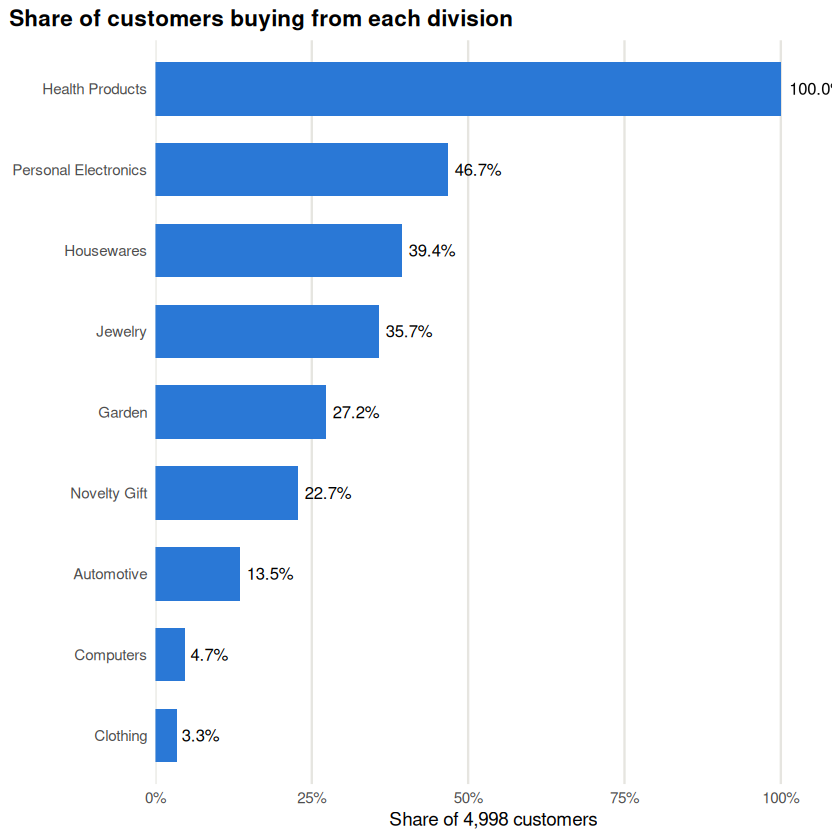

In [8]:
ggplot(penetration, aes(reorder(Division, Share), Share)) +
geom_col(fill = col_main, width = 0.65) +
geom_text(aes(label = percent(Share, 0.1)), hjust = -0.15, size = 3.4) +
coord_flip() +
scale_y_continuous(labels = percent, limits = c(0, 1.08), expand = c(0, 0)) +
labs(title = "Share of customers buying from each division",
     x = NULL, y = "Share of 4,998 customers") +
theme_report + 
theme(panel.grid.major.y = element_blank(),
      panel.grid.major.x = element_line(colour = "#e6e5e0"))

Three key findings emerge from the descriptive analysis:

•  Health Products (100%) was purchased by every customer, suggesting that the dataset represents an existing Health Products customer base. Since this division has no variation in purchase behaviour, it provides no useful information for identifying cross-selling patterns and is therefore excluded from association rule mining.

•  Personal Electronics (46.7%), Housewares (39.4%) and Jewelry (35.7%) are the most popular divisions. Their high baseline purchase rates mean that they are likely to generate sales regardless of which customers receive their catalogs.

•  Computers (4.7%) and Clothing (3.3%) are niche divisions. Association rules involving these divisions are based on relatively few customers and should therefore be interpreted with caution.


To further understand existing cross-buying behaviour, the analysis examines the number of divisions from which each customer has made a purchase.

In [8]:
ccs$n_div <- rowSums(ccs[divisions])
ccs$n_div_exHP  <- ccs$n_div - ccs$`Health Products`   # exclude Health Products
 
summary(ccs$n_div)
table(Divisions_bought = ccs$n_div)
cat("Customers who bought ONLY from Health Products:",
    sum(ccs$n_div_exHP == 0), sprintf("(%.1f%%)", 100 * mean(ccs$n_div_exHP == 0)), "\n")
cat("Customers with 2+ divisions (cross-buyers)    :",
    sum(ccs$n_div >= 2), sprintf("(%.1f%%)", 100 * mean(ccs$n_div >= 2)), "\n")

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   1.00    2.00    3.00    2.93    4.00    9.00 

Divisions_bought
   1    2    3    4    5    6    7    8    9 
1002 1358 1022  759  464  264  106   18    5 

Customers who bought ONLY from Health Products: 1002 (20.0%) 
Customers with 2+ divisions (cross-buyers)    : 3996 (80.0%) 


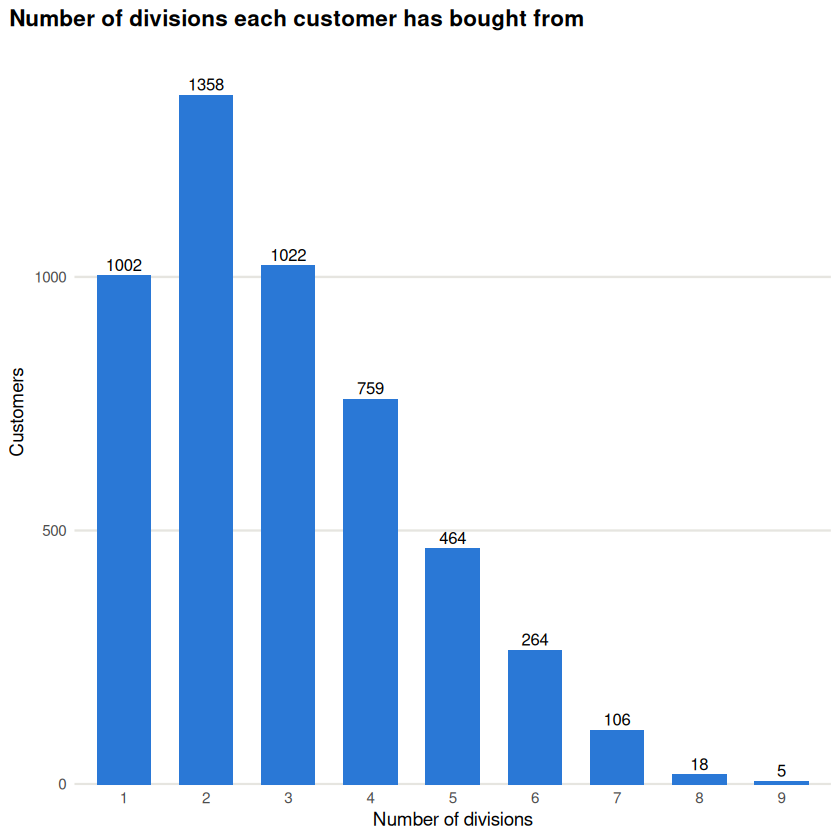

In [10]:
ggplot(ccs, aes(factor(n_div))) +
geom_bar(fill = col_main, width = 0.65) +
geom_text(stat = "count", aes(label = after_stat(count)), vjust = -0.4, size = 3.4) +
scale_y_continuous(expand = expansion(mult = c(0, 0.08))) +
labs(title = "Number of divisions each customer has bought from",
     x = "Number of divisions", y = "Customers") +
theme_report

Customers purchased from an average of 2.9 divisions (median = 3), including Health Products. While 20% (1,002 customers) purchased exclusively from Health Products, the remaining 80% had purchased from at least one other division. This indicates that cross-buying is already common, providing a favourable foundation for a cross-selling programme.


To identify which divisions are frequently purchased together, support, confidence, and lift are calculated for every pair of divisions using their co-purchase counts before applying the Apriori algorithm. The resulting lift values are presented in a heat map to highlight associations between divisions.

In [9]:
# Pairwise co-purchase
X <- as.matrix(ccs[divisions])
N <- nrow(X)
co <- crossprod(X)    # co[i, j] = customers buying from both i and j
p <- diag(co) / N     # support of each single division
 
supp_pair <- co / N    # P(A and B)
conf_pair <- sweep(co, 1, diag(co), "/")  # P(B | A), row = A, column = B
lift_pair <- supp_pair / outer(p, p)   # P(A and B) / (P(A) P(B))

# a division paired with itself is meaningless, so blank out the diagonal
diag(conf_pair) <- NA
diag(lift_pair) <- NA
 
round(lift_pair, 2)

,Clothing,Housewares,Health Products,Automotive,Personal Electronics,Computers,Garden,Novelty Gift,Jewelry
Clothing,NA,1.85,1,1.35,1.28,4.40,1.25,1.71,1.70
Housewares,1.85,NA,1,1.27,1.28,1.72,1.24,1.51,1.39
Health Products,1.00,1.00,NA,1.00,1.00,1.00,1.00,1.00,1.00
Automotive,1.35,1.27,1,NA,1.32,1.52,2.33,1.81,1.56
Personal Electronics,1.28,1.28,1,1.32,NA,1.07,1.28,1.59,1.18
Computers,4.40,1.72,1,1.52,1.07,NA,1.29,1.33,1.77
Garden,1.25,1.24,1,2.33,1.28,1.29,NA,1.81,1.31
Novelty Gift,1.71,1.51,1,1.81,1.59,1.33,1.81,NA,1.32
Jewelry,1.70,1.39,1,1.56,1.18,1.77,1.31,1.32,NA


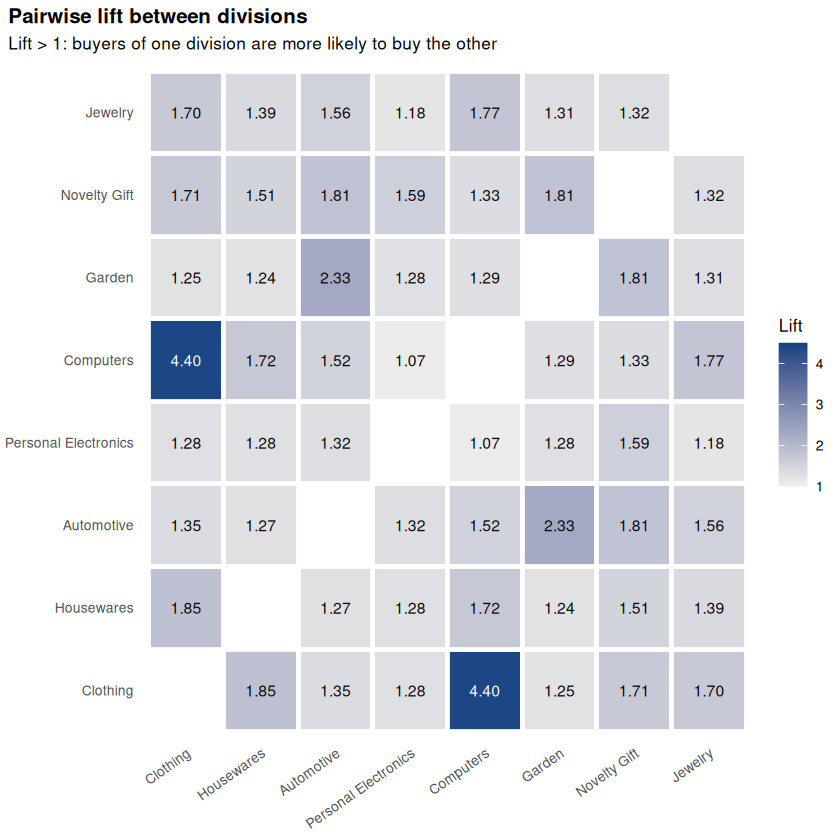

In [10]:
# Heat map of pairwise lift (Health Products excluded: it is bought by everyone, lift = 1)
keep <- setdiff(divisions, "Health Products")
lift_long <- as.data.frame(as.table(lift_pair[keep, keep])) %>%
  setNames(c("A", "B", "Lift")) %>%
  filter(A != B)
 
ggplot(lift_long, aes(B, A, fill = Lift)) +
geom_tile(colour = "white", linewidth = 1) +
geom_text(aes(label = sprintf("%.2f", Lift)), size = 3.2,
          colour = ifelse(lift_long$Lift > 2.6, "white", "#0b0b0b")) +
scale_fill_gradient(low = "#f0efec", high = "#104281", limits = c(1, 4.5)) +
labs(title = "Pairwise lift between divisions",
     subtitle = "Lift > 1: buyers of one division are more likely to buy the other",
     x = NULL, y = NULL) +
theme_minimal(base_size = 10) +
theme(axis.text.x = element_text(angle = 35, hjust = 1),
      panel.grid = element_blank(), plot.title = element_text(face = "bold"),
      plot.title.position = "plot")

All division pairs have lift values above 1, ranging from 1.07 to 4.40. This indicates that customers who purchase from one division are generally more likely to purchase from another, suggesting broad cross-buying behaviour among active catalog customers. Health Products consistently has a lift of exactly 1, confirming that it provides no additional information about purchasing associations. 

The strongest associations are:

•  Clothing and Computers (lift = 4.40): The strongest association, but it involves only 34 customers (0.7%). Despite its high lift, the small customer base makes it more interesting than actionable.

•  Automotive and Garden (lift = 2.33): A relatively strong association involving 427 customers, potentially indicating a home-owner or outdoor-oriented customer segment.

•  Garden and Novelty Gift (lift = 1.81), Automotive and Novelty Gift (lift = 1.81), and Clothing and Housewares (lift = 1.85): These pairs also show notable purchasing associations.

The weakest association is between Personal Electronics and Computers (lift = 1.07). Despite their apparent product similarity, customers purchasing from both divisions show little more overlap than would be expected by chance.


### Association Rules Analysis
To identify more specific cross-selling opportunities, the purchase data are converted into transactions, with each customer's purchased divisions treated as a single basket. Health Products is excluded because it appears in every basket and therefore provides no useful information for identifying purchasing associations.

In [11]:
# Convert into transactions
# Health Products is dropped
trans <- as(as.matrix(ccs[keep]) == 1, "transactions")
summary(trans)
round(itemFrequency(trans), 3)

transactions as itemMatrix in sparse format with
 4998 rows (elements/itemsets/transactions) and
 8 columns (items) and a density of 0.2415 

most frequent items:
Personal Electronics           Housewares              Jewelry               Garden 
                2336                 1967                 1784                 1360 
        Novelty Gift              (Other) 
                1137                 1073 

element (itemset/transaction) length distribution:
sizes
   0    1    2    3    4    5    6    7    8 
1002 1358 1022  759  464  264  106   18    5 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    1.00    2.00    1.93    3.00    8.00 

includes extended item information - examples:
      labels
1   Clothing
2 Housewares
3 Automotive

Clothing           Housewares           Automotive Personal Electronics 
               0.033                0.394                0.135                0.467 
           Computers               Garden         Novelty Gift              Jewelry 
               0.047                0.272                0.227                0.357

The transaction object contains 4,998 baskets across eight divisions. The basket-size distribution is shifted down by having Health Products removed. Now 1,002 baskets are empty and cannot generate association rules.


The Apriori algorithm is then applied to identify rules of the form *IF* a customer purchases {A}, *THEN* the customer also purchases {B}. The thresholds are set to ensure that each rule covers at least approximately 100 customers (support ≥ 2%) and has a minimum confidence of 40%. Redundant rules are removed, particularly longer rules that offer no improvement over simpler rule they contain.

In [12]:
# Mine association rules with the apriori algorithm
rules_all <- apriori(trans,
                     parameter = list(support = 0.02, confidence = 0.40, minlen = 2),
                     control   = list(verbose = FALSE))
cat("Rules found:", length(rules_all), "\n")
 
# Remove redundant rules
rules <- rules_all[!is.redundant(rules_all)]
cat("Non-redundant rules:", length(rules), "\n")
summary(quality(rules)[, c("support", "confidence", "lift", "count")])

Rules found: 153 
Non-redundant rules: 136 


    support         confidence         lift          count     
 Min.   :0.0200   Min.   :0.404   Min.   :1.07   Min.   : 100  
 1st Qu.:0.0342   1st Qu.:0.534   1st Qu.:1.59   1st Qu.: 171  
 Median :0.0510   Median :0.618   Median :1.79   Median : 255  
 Mean   :0.0639   Mean   :0.627   Mean   :1.93   Mean   : 320  
 3rd Qu.:0.0809   3rd Qu.:0.709   3rd Qu.:2.20   3rd Qu.: 404  
 Max.   :0.2355   Max.   :0.901   Max.   :3.35   Max.   :1177  

The Apriori algorithm identified 153 rules, of which 136 remained after removing redundant rules. Across the retained rules, support ranges from 2% to 23.6%, confidence from 40% to 90%, and lift from 1.07 to 3.35. All rules have a lift above 1, indicating that the associated item combinations occur more frequently than would be expected by chance.


The strongest rules are identified using two ranking criteria: lift which measures the strength of an association, and confidence, which measures the probability that the rule holds.

In [13]:
# Top 10 rules ranked by lift
top10 <- head(sort(rules, by = "lift"), 10)
inspect(top10)
 
# Top 10 rules ranked by confidence
inspect(head(sort(rules, by = "confidence"), 10))

     lhs                        rhs          support confidence coverage  lift count
[1]  {Personal Electronics,                                                         
      Garden,                                                                       
      Novelty Gift,                                                                 
      Jewelry}               => {Automotive} 0.02401     0.4511  0.05322 3.345   120
[2]  {Garden,                                                                       
      Novelty Gift,                                                                 
      Jewelry}               => {Automotive} 0.02781     0.4413  0.06303 3.272   139
[3]  {Housewares,                                                                   
      Personal Electronics,                                                         
      Garden,                                                                       
      Novelty Gift}          => {Automotive} 0.02421     0.4201  

Ranked by lift, the strongest rules centre on a cluster of Automotive, Garden, Novelty Gift, Jewelry and Personal Electronics. For example, customers who purchased from Personal Electronics, Garden, Novelty Gift and Jewelry also purchased Automotive 45% of the time, compared with a base rate of 13.5%. This represents a lift of 3.35. Although these associations are strong, they cover relatively small customer groups (2–4%).

Ranked by confidence, almost all the strongest rules predict purchases from Personal Electronics, with confidence reaching 90%. However, their lift is only about 1.8–1.9, because nearly half of all customers already purchase from this division.

This contrast highlights an important practical distinction: high-lift rules reveal stronger-than-expected associations, whereas high-confidence rules identify purchases that are more likely to occur. For catalog selection, confidence indicates the likelihood of a sale, while lift shows how much of that likelihood is attributable to the association rather than the division's general popularity.


The statistics for the rule {Automotive} ⇒ {Garden} are calculated manually and compared with the corresponding results from arules.

In [14]:
# Calculating the rule {Automotive} => {Garden} by hand
n_auto <- sum(ccs$Automotive)
n_garden <- sum(ccs$Garden)
n_auto_garden <- sum(ccs$Automotive == 1 & ccs$Garden == 1)
 
support <- n_auto_garden / N
confidence <- n_auto_garden / n_auto
benchmark <- n_garden / N               # chance of buying Garden with no information
lift <- confidence / benchmark
 
data.frame(Automotive_buyers = n_auto, Garden_buyers = n_garden,
           Both = n_auto_garden, Support = support, Confidence = confidence,
           Benchmark = benchmark, Lift = lift)
 
# The same rule as reported by arules
inspect(subset(rules_all, lhs %ain% "Automotive" & rhs %in% "Garden" & size(lhs) == 1))

Automotive_buyers,Garden_buyers,Both,Support,Confidence,Benchmark,Lift
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
674,1360,427,0.08543,0.6335,0.2721,2.328


    lhs             rhs      support confidence coverage lift  count
[1] {Automotive} => {Garden} 0.08543 0.6335     0.1349   2.328 427  


The hand calculations match the arules output exactly. The three statistics can be interpreted as follows:

•  **Support = 8.5%.** Of the 4,998 customers, 427 purchased from both Automotive and Garden. Support measures how frequently an item combination occurs and how many customers a rule covers. Rules with low support may indicate strong associations but affect relatively few customers.

•  **Confidence = 63.4%.** Of the 674 Automotive customers, 427 (63.4%) also purchased from Garden. Confidence estimates the probability that a customer who purchases the item in the *IF* condition will also purchase the item in the *THEN* condition. In this case, it represents the expected success rate of including a Garden catalog with an Automotive order.

•  **Lift = 2.33.** Without considering Automotive purchases, the probability of a customer purchasing from Garden is 27.2%. Knowing that a customer purchased from Automotive increases the probability to 63.4%, or 2.33 times the baseline rate. Lift is calculated as confidence divided by the baseline probability. A lift of 1 indicates no association, a value above 1 indicates a positive association, and a value below 1 indicates a negative association.

An important distinction is that lift is symmetric: the rule Garden ⇒ Automotive also has a lift of 2.33. Confidence, however, is directional: only 31.4% of Garden customers also purchased from Automotive. Therefore, the direction of a rule matters when deciding which division to promote.


The scatter plot displays each rule as a dot, positioned according to its support and confidence, shaded by lift and sized according to the number of divisions it contains.

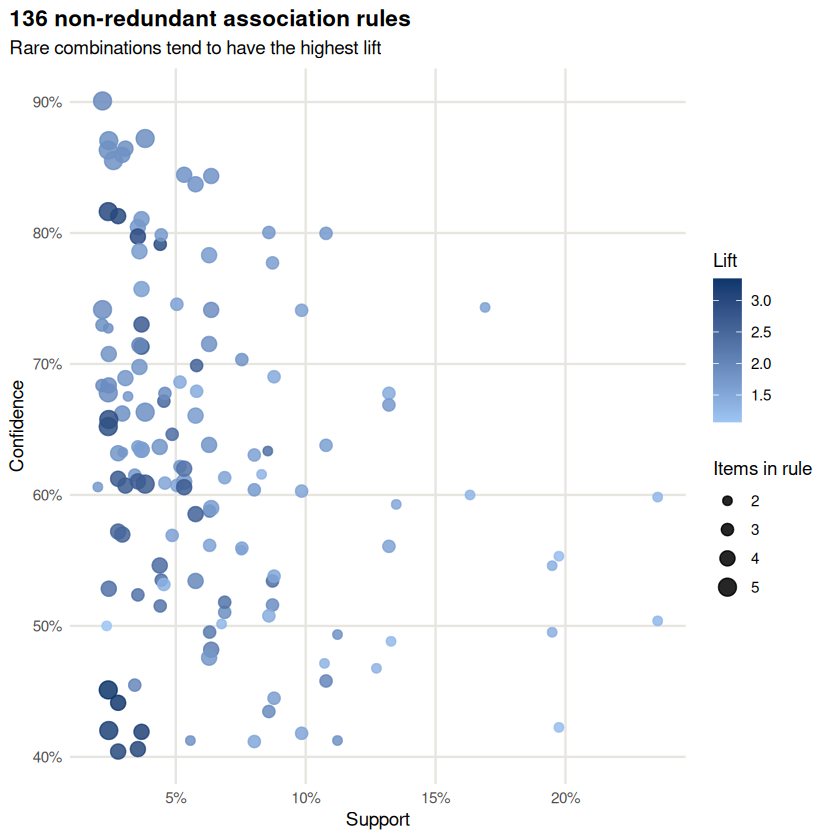

In [15]:
# Support vs confidence, shaded by lift
rq <- as.data.frame(quality(rules))
rq$items <- factor(size(rules)) # number of items in the rule
 
ggplot(rq, aes(support, confidence, colour = lift, size = items)) +
geom_point(alpha = 0.85) +
scale_colour_gradient(low = "#9ec5f4", high = "#0d366b", name = "Lift") +
scale_size_manual(values = c(2, 2.8, 3.6, 4.4, 5.2), name = "Items in rule") +
scale_x_continuous(labels = percent) + scale_y_continuous(labels = percent) +
labs(title = sprintf("%d non-redundant association rules", length(rules)),
     subtitle = "Rare combinations tend to have the highest lift",
     x = "Support", y = "Confidence") +
theme_report + theme(panel.grid.major.x = element_line(colour = "#e6e5e0"))

The chart illustrates a typical trade-off: the darkest points representing the highest-lift rules, tend to have low support. These are mostly longer rules with four or five divisions describing small, highly engaged customer groups. Rules with high support (on the right-hand side) tend to be shorter, involve popular catalogs, and have more modest lift. An effective cross-selling rule should have sufficient support to reach a meaningful number of customers, high confidence to generate sales, and a lift above 1 to outperform random selection.


### Which Catalog Should Exeter Cross-Promote?
Supposed a customer has just purchased from one division. In a cross-selling lookup table, for each division A, the table identifies the catalog B with the highest confidence P(B | A). This is then compared with the average confidence across the other seven catalogs, representing the expected success rate of selecting a catalog at random.

In [18]:
# Cross-sell lookup table
lookup <- lapply(keep, function(a) {
  conf_b <- conf_pair[a, setdiff(keep, a)]  # P(B | A) for the other 7 catalogs
  best <- names(which.max(conf_b))
  data.frame(Purchased = a,
             Buyers = co[a, a],
             Best_pick = best,
             Confidence = max(conf_b),
             Lift = lift_pair[a, best],
             Random_avg = mean(conf_b),    # expected rate if B chosen at random
             Gain_x = max(conf_b) / mean(conf_b))
}) %>% bind_rows() %>% arrange(desc(Buyers))
lookup %>% mutate(across(where(is.double), ~ round(.x, 2)))
 
# Highest-LIFT alternative for each division
lapply(keep, function(a) {
l <- lift_pair[a, setdiff(keep, a)]
data.frame(Purchased = a, Highest_lift_catalog = names(which.max(l)),
           Lift = round(max(l), 2),
           Confidence = round(conf_pair[a, names(which.max(l))], 2))
}) %>% bind_rows()

Purchased,Buyers,Best_pick,Confidence,Lift,Random_avg,Gain_x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Personal Electronics,2336,Housewares,0.50,1.28,0.27,1.85
Housewares,1967,Personal Electronics,0.60,1.28,0.30,2.01
Jewelry,1784,Personal Electronics,0.55,1.18,0.30,1.84
Garden,1360,Personal Electronics,0.60,1.28,0.34,1.76
Novelty Gift,1137,Personal Electronics,0.74,1.59,0.38,1.95
Automotive,674,Garden,0.63,2.33,0.41,1.56
Computers,234,Housewares,0.68,1.72,0.40,1.68
Clothing,165,Housewares,0.73,1.85,0.44,1.67


Purchased,Highest_lift_catalog,Lift,Confidence
<chr>,<chr>,<dbl>,<dbl>
Clothing,Computers,4.40,0.21
Housewares,Clothing,1.85,0.06
Automotive,Garden,2.33,0.63
Personal Electronics,Novelty Gift,1.59,0.36
Computers,Clothing,4.40,0.15
Garden,Automotive,2.33,0.31
Novelty Gift,Garden,1.81,0.49
Jewelry,Computers,1.77,0.08


In the first table, Confidence represents the expected success rate of the best catalog choice, Random_avg represents the expected success rate of selecting a catalog at random, and Gain_x measures the ratio between the two. The results provide the following practical recommendations for Exeter's shipping department:

•  **Personal Electronics order:** Enclose Housewares (50% expected success compared with 27% at random).

•  **Housewares, Jewelry, Garden or Novelty Gift order:** Enclose Personal Electronics (55–74% expected success). 

•  **Automotive order:** Enclose Garden (63% expected success, with a lift of 2.33). This is the only recommendation that does not simply favour a popular catalog.

•  **Computers or Clothing order:** Enclose Housewares (68–73% expected success).

Across all divisions, selecting a catalog based on the association rules is approximately 1.6 to 2.0 times more likely to succeed than a random selection, with an average improvement of about 1.8 times.

The second table highlights why lift alone is insufficient for selecting catalogs. The highest-lift recommendation may involve a niche catalog with very low confidence. For example, recommending Clothing to  Housewares customers produces a lift of 1.85 but has only 6% confidence.

To assess whether the recommendations generalise to unseen customers, the rules are developed using 70% of the customers and evaluated on the remaining 30%. For each test customer, one purchase is treated as the order being shipped and one catalog is recommended. Four strategies are compared: random catalog selection, highest-lift selection, selection of the most popular catalog not yet purchased, and association-rule selection based on the highest confidence.

In [20]:
# Rough estimate of the benefit, using a 70/30 train-test split.
Xk <- as.matrix(ccs[keep])
idx <- sample(N, size = round(0.7 * N))
train <- Xk[idx, ];  test <- Xk[-idx, ]
 
co_tr <- crossprod(train)
conf_tr <- sweep(co_tr, 1, diag(co_tr), "/")
pop_tr <- colMeans(train)
 
test <- test[rowSums(test) >= 1, ]          # a purchase is needed to trigger a promotion
trigger <- apply(test, 1, function(r) sample(names(r)[r == 1], 1))

best_of <- function(scores, a) names(which.max(scores[setdiff(keep, a)]))
lift_tr <- conf_tr / matrix(pop_tr, length(keep), length(keep), byrow = TRUE)
 
pick_random <- sapply(trigger, function(a) sample(setdiff(keep, a), 1))
pick_popular <- sapply(trigger, function(a) best_of(pop_tr, a))
pick_rules <- sapply(trigger, function(a) best_of(conf_tr[a, ], a))
pick_lift <- sapply(trigger, function(a) best_of(lift_tr[a, ], a))
 
hit <- function(pick) mean(test[cbind(seq_len(nrow(test)), match(pick, keep))] == 1)
results <- data.frame(Strategy = c("Random catalog", "Highest-lift catalog",
                          "Most popular catalog", "Association rules (confidence)"),
                      Hit_rate = c(hit(pick_random), hit(pick_lift),
                                   hit(pick_popular), hit(pick_rules)))
results$Gain_vs_random <- results$Hit_rate / results$Hit_rate[1]
cat("Test customers evaluated:", nrow(test), "\n")
results
 
# How the rule-based pick differ from simply sending the most popular catalog
cat("Rule-based pick differs from 'most popular' for",
    percent(mean(pick_rules != pick_popular), 0.1), "of test customers\n")
table(Trigger = trigger, Recommended = pick_rules)

Test customers evaluated: 1179 


Strategy,Hit_rate,Gain_vs_random
<chr>,<dbl>,<dbl>
Random catalog,0.1985,1.0000
Highest-lift catalog,0.1552,0.7821
Most popular catalog,0.3969,2.0000
Association rules (confidence),0.3961,1.9957


Rule-based pick differs from 'most popular' for 28.9% of test customers


                      Recommended
Trigger                Garden Housewares Personal Electronics
  Automotive               69          0                    0
  Clothing                  0         18                    0
  Computers                 0         18                    0
  Garden                    0          0                  156
  Housewares                0          0                  256
  Jewelry                   0        236                    0
  Novelty Gift              0          0                  109
  Personal Electronics      0        317                    0

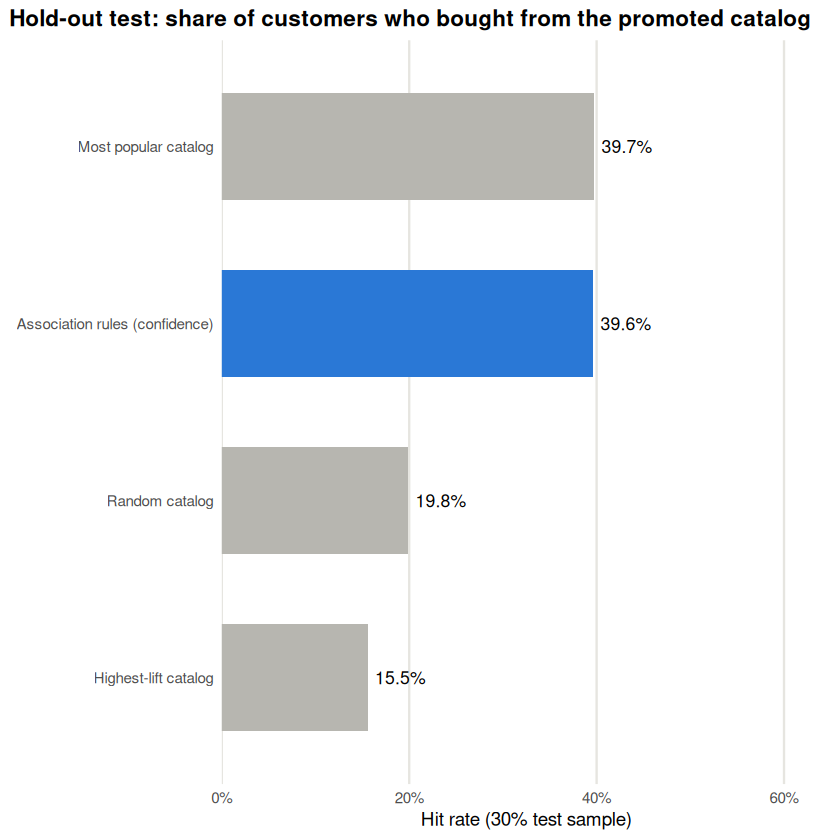

In [21]:
ggplot(results, aes(reorder(Strategy, Hit_rate), Hit_rate,
       fill = Strategy == "Association rules (confidence)")) +
geom_col(width = 0.6) +
geom_text(aes(label = percent(Hit_rate, 0.1)), hjust = -0.15, size = 3.6) +
scale_fill_manual(values = c(`TRUE` = col_main, `FALSE` = col_grey), guide = "none") +
coord_flip() +
scale_y_continuous(labels = percent, limits = c(0, 0.65), expand = c(0, 0)) +
labs(title = "Hold-out test: share of customers who bought from the promoted catalog",
     x = NULL, y = "Hit rate (30% test sample)") +
theme_report + 
theme(panel.grid.major.y = element_blank(),
      panel.grid.major.x = element_line(colour = "#e6e5e0"))

Across the 1,179 test customers, the results show three key findings:

•  A randomly selected catalog achieves a hit rate of approximately 20%, compared with 40% for the association-rule recommendation. This provides a rough estimate that an informed catalog choice can double the likelihood of a subsequent purchase.

•  Selecting the most popular catalog achieves a hit rate of 39.7%, almost identical to the rule-based approach. Although the rule-based recommendation differs from the popular choice for 29% of customers (e.g. Automotive → Garden, Jewelry → Housewares), these alternatives perform comparably rather than better.

•  Its hit rate of 15.5% is below that of random selection because it tends to favour niche catalogs.

Overall, most of the improvement comes from directing promotions towards popular catalogs with broad customer appeal. Specific associations provide additional value for certain segments, particularly Automotive and Garden buyers, as well as customers with several previous purchases, for whom confidence reaches 80–90%.

These hit rates should be interpreted as proxies rather than actual coupon response rates. They measure whether customers purchased from a recommended catalog at some point, not whether a promotion generated an additonal purchase. Actual coupon redemption rates are likely to be considerably lower, but the relative performance of the strategies provides a useful basis for comparison.


### Conclusion
The association rule analysis shows that Exeter's customers purchase across multiple divisions. 80% have purchased from more than one division and every pair of divisions has a lift above 1. The strongest specific association is between Automotive and Garden (lift 2.33), within a broader cluster involving Novelty Gift, Jewelry and Personal Electronics. Support indiates how many customers a rule covers, confidence estimates the expected success rate of a promotion, and lift measures the strength of the association relative to chance.

The hold-out test suggests that selecting catalogs based on confidence can approximately double the likelihood of a cross-sale compared with random selection (40% versus 20%). However, much of this improvement comes from favouring popular catalogs. A simple lookup table captures most of the potential value, while more specific associations provide additional opportunities for targeted promotions. An A/B test is recommended to validate these findings before full implementation.


### Recommendations
•  Enclose Housewares with Personal Electronics orders, Garden with Automotive orders, and Personal Electronics with most other orders. This approach approximately doubles the expected hit rate compared with random catalog selection.

•  Multi-item rules can achieve 80–90% confidence among customers with several previous purchases. For example, {Automotive, Novelty Gift} ⇒ Garden achieves 79% confidence and a lift of 2.91.

•  Avoid selecting niche catalogs, particularly Clothing and Computers, based on lift alone.

•  Assign one group to receive association-rule-based catalog recommendations and another to receive random recommendations. Compare actual coupon redemption rates before proceeding with a full rollout.


### Limitations
•  The data indicate whether a customer purchased from a division, but not when, how frequently, or how much. Consequently, the rules capture purchasing co-occurrence rather than purchase sequences or causal relationships.

•  Every customer purchased from Health Products, which may limit the representativeness of the sample relative to Exeter's broader customer base.

•  Rules involving Clothing and Computers are based on relatively few customers and should therefore be interpreted cautiously.

•  The hold-out hit rate estimates potential coupon response rather than actual redemption. Although it overstates the absolute likelihood of success, it remains useful for comparing the relative performance of the recommendation strategies.